# Well analysis

## Import Library

In [1]:
# std
import os
import re
from pathlib import Path

# third-party
import geopandas as gpd
import ipywidgets as widgets
import lasio as ls
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import pyplot as plt
from rich import print
from scipy.optimize import nnls
from scipy.spatial import cKDTree

if os.getcwd().endswith("notebooks"):
    os.chdir("../")
print(f"Current working directory: {os.getcwd()}")

Current working directory: /Volumes/X31/01.Projects/atem

## Data path setting

In [2]:
# Well Data directory.
well_data_dir: str = Path("data//well")
# Shape file location.
water_well_shp = well_data_dir / "WaterWell_HQ_LAS/Shapefile/WWLAS_CLC_HQ.shp"
print(water_well_shp)
coal_hole_shp = well_data_dir / "CoalHoles_HQ_LAS/Shapefile/CoalHole_CLC_HQ.shp"
print(coal_hole_shp)

data/well/WaterWell_HQ_LAS/Shapefile/WWLAS_CLC_HQ.shp

data/well/CoalHoles_HQ_LAS/Shapefile/CoalHole_CLC_HQ.shp

In [3]:
# .geometry attribute.
ww_gdf = gpd.read_file(water_well_shp).to_crs(epsg=26_912)
ch_gdf = gpd.read_file(coal_hole_shp).to_crs(epsg=26_912)

In [4]:
# DTW
# Wells deeper than 100 m and records with static water levels greater than 50 m below ground surface were excluded.
# Only wells where the static water level occurred within the screened interval (±5 m) were retained
tmp = pd.read_csv(
    "data/Depth_to_Watertable/depth-to-water.csv",
)
tmp = tmp.rename(columns={
    "GicWellId": "name",
    "WellId": "name2",
    "Longitude": "longitude",
    "Latitude": "latitude",
    "WellReportId": "name3",
    "TotalDepthDrilled": "total_depth",
    "DrillingMethod": "drilling_method",
    "DrillingEndDate": "drilling_end_date",
    "ArtesianFlowFlag": "flag",
    "PumpTestId": "pump_id",
    "TestDate": "test_date",
    "StaticWaterLevel": "static_water_level",
    "IntervalFrom": "interval_from",
    "IntervalTo": "interval_to",
})
depth_to_water = gpd.GeoDataFrame(
    tmp,
    geometry=gpd.points_from_xy(tmp["longitude"], tmp["latitude"]),
    crs = "EPSG:4326"
)
depth_to_water = depth_to_water.to_crs(epsg=26_912)
depth_to_water["x"] = depth_to_water.geometry.x
depth_to_water["y"] = depth_to_water.geometry.y

In [5]:
# Extract well names.
def pick_name(row, candidates):
    for col in candidates:
        if col in row.index and not pd.isna(row[col]):
            text = str(row[col]).strip()
            if text != "":
                return text
    return None


# Make a container for all well records.
well_records = []

# For Water well.
for _, row in ww_gdf.iterrows():
    if row.geometry is None or row.geometry.is_empty:
        continue
    # Extract well name defined with priority: LAS_FI_NAM > Name > SHORTNAME from a given row.
    name = pick_name(row, ["LAS_FI_NAM", "SHORTNAME"])
    if name is None:
        continue
    well_records.append(
        {
            "well_type": "WaterWell",
            "well_name": name,
            "well_id": pick_name(row, ["GIC_W_ID", "GIC_WELL_I"]),
            "x": float(row.geometry.x),
            "y": float(row.geometry.y),
            "ground_elevation_m": pd.to_numeric(row.get("EL_DEM15_M"), errors="coerce"),
        }
    )

# For Coal hole.
for _, row in ch_gdf.iterrows():
    if row.geometry is None or row.geometry.is_empty:
        continue
    name = pick_name(row, ["Name", "Name_1"])
    if name is None:
        continue
    well_records.append(
        {
            "well_type": "CoalHole",
            "well_name": name,
            "well_id": pick_name(row, ["Source_Id"]),
            "x": float(row.geometry.x),
            "y": float(row.geometry.y),
            "ground_elevation_m": pd.to_numeric(row.get("El_AB100"), errors="coerce"),
        }
    )
well_df = pd.DataFrame(well_records)

In [6]:
# Well Type, Well Name, Well ID, X, Y
well_df

,well_type,well_name,well_id,x,y,ground_elevation_m
0,WaterWell,153840-a,153840.0,307835.034573,5.563906e+06,1062.000000
1,WaterWell,153842-a,153842.0,307865.241639,5.563872e+06,1060.000000
2,WaterWell,153926-a,153926.0,389121.199688,5.674698e+06,945.000000
3,WaterWell,153843-a,153843.0,393054.360097,5.563842e+06,812.000000
4,WaterWell,153844-a,153844.0,393724.628345,5.559780e+06,822.000000
...,...,...,...,...,...,...
72,CoalHole,TH77-76,55.0,411112.686984,5.580320e+06,771.558777
73,CoalHole,TH78-76,55.0,401396.586685,5.583678e+06,813.697815
74,CoalHole,TH79-76,55.0,420839.482599,5.577134e+06,757.945068
75,CoalHole,TH9-83,55.0,414546.097295,5.589883e+06,775.880127


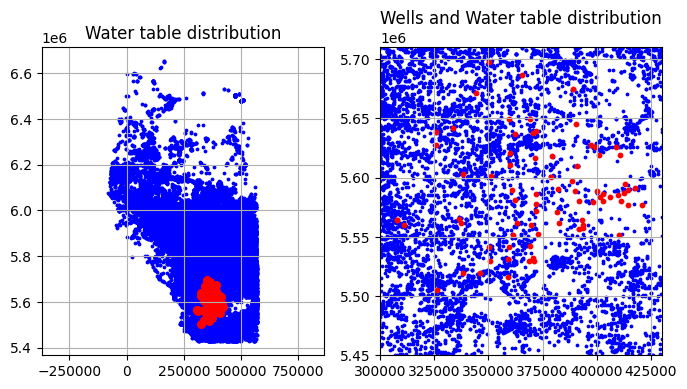

In [7]:
plt.figure(figsize=(8, 4))
plt.subplot(121)
plt.scatter(depth_to_water["x"], depth_to_water["y"], s=3, c="blue", label="Depth to Water")
plt.scatter(well_df["x"], well_df["y"], s=30, c="red", label="Wells")
plt.axis("equal")
plt.title("Water table distribution")
plt.grid()
plt.subplot(122)
plt.scatter(depth_to_water["x"], depth_to_water["y"], s=3, c="blue", label="Depth to Water")
plt.scatter(well_df["x"], well_df["y"], s=10, c="red", label="Wells")
plt.title("Wells and Water table distribution")
plt.xlim(0.3e6, 0.43e6)
plt.ylim(5.45e6, 5.71e6)
plt.grid()

In [8]:
tree = cKDTree(depth_to_water[["x", "y"]])
temp_dis = []
temp_idx = []

for row in range(well_df.shape[0]):
    test_x = float(well_df.loc[row, "x"])
    test_y = float(well_df.loc[row, "y"])
    distance, valid_index = tree.query([test_x, test_y], k=1)
    temp_dis.append(distance)
    temp_idx.append(valid_index)

Text(0, 0.5, 'Counts')

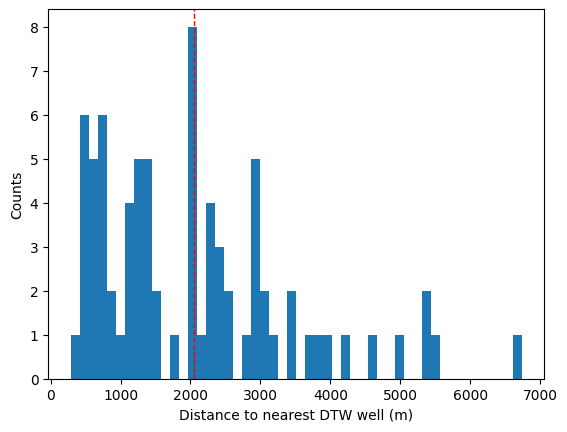

In [9]:
plt.hist(temp_dis, bins=50)
plt.axvline(np.mean(temp_dis), color="red", linestyle="dashed", linewidth=1, label="Mean")
plt.xlabel("Distance to nearest DTW well (m)")
plt.ylabel("Counts")

In [10]:
# Data is too sparse....



# cutoff_distance:float = 2_000.0

# for row in range(well_df.shape[0]):
#     if temp_dis[row] < cutoff_distance:
#         values = depth_to_water.loc[temp_idx[row], "static_water_level"]
#     else:
#         values = np.nan
#     well_df.loc[row, "depth_to_water"] = values

### Local DTW depth from the provincial prediction grid

The prediction grid stores depth below local ground, so it can be compared directly with the AEM/log depths below ground. Its estimated water-table elevation is also calculated from each analysis collar elevation. The source describes moderate cross-validation performance (R² = 0.62), so this is a model-based sensitivity run, not a direct water-level observation. Absolute elevations combine the collar elevation fields (`EL_DEM15_M` or `El_AB100`) with the gridded DTW and should be treated as approximate; the above/below split uses local depth, avoiding vertical-datum offsets.

In [11]:
from PIL import Image
from pyproj import Transformer

dtw_grid_path = Path("data/Depth_to_Watertable/depth-to-water-250m.tif")
dtw_grid = Image.open(dtw_grid_path)
pixel_scale = dtw_grid.tag_v2[33550] # Pixel scale
tiepoint = dtw_grid.tag_v2[33922] # 기준점..
geo_keys = dtw_grid.tag_v2[34735] # GeoTIFF 
projected_crs = next(
    geo_keys[7 + 4 * i]
    for i in range(geo_keys[3])
    if geo_keys[4 + 4 * i] == 3072 # 투영좌표계
)
if projected_crs != 3400:
    raise ValueError(f"Unexpected DTW grid CRS EPSG:{projected_crs}; expected EPSG:3400.")
if pixel_scale[0] <= 0 or pixel_scale[1] <= 0:
    raise ValueError(f"Unsupported DTW grid pixel scale: {pixel_scale}.")

dtw_grid_nodata = float(dtw_grid.tag_v2.get(42113, -99999))
grid_x0, grid_y0 = float(tiepoint[3]), float(tiepoint[4])

# Coordinate transformation from WGS84 (EPSG:26912) to the projected CRS of the DTW grid.
to_dtw_grid = Transformer.from_crs(26_912, projected_crs, always_xy=True)

def sample_modelled_dtw_depth(x, y):
    """Sample modelled depth below local ground from the 250 m DTW grid."""
    grid_x, grid_y = to_dtw_grid.transform(float(x), float(y))
    column = int(np.floor((grid_x - grid_x0) / pixel_scale[0]))
    row = int(np.floor((grid_y0 - grid_y) / pixel_scale[1]))
    if not (0 <= column < dtw_grid.width and 0 <= row < dtw_grid.height):
        return np.nan

    value = float(dtw_grid.getpixel((column, row)))
    if not np.isfinite(value) or value == dtw_grid_nodata:
        return np.nan
    return value

well_df["dtw_grid_depth_m"] = [
    sample_modelled_dtw_depth(row.x, row.y)
    for row in well_df.itertuples()
]
well_df["water_table_elevation_m"] = (
    well_df["ground_elevation_m"] - well_df["dtw_grid_depth_m"]
)

print(
    f"DTW grid values at analysis wells: "
    f"{well_df['dtw_grid_depth_m'].notna().sum()}/{len(well_df)}; "
    f"grid resolution: {pixel_scale[0]:.0f} m"
)
print(
    "Modelled DTW depth range: "
    f"{well_df['dtw_grid_depth_m'].min():.2f} to "
    f"{well_df['dtw_grid_depth_m'].max():.2f} m below local ground"
)
print(
    "Collar elevation range: "
    f"{well_df['ground_elevation_m'].min():.2f} to "
    f"{well_df['ground_elevation_m'].max():.2f} m; "
    "modelled water-table elevation range: "
    f"{well_df['water_table_elevation_m'].min():.2f} to "
    f"{well_df['water_table_elevation_m'].max():.2f} m"
)

DTW grid values at analysis wells: 77/77; grid resolution: 250 m

Modelled DTW depth range: 2.59 to 25.89 m below local ground

Collar elevation range: 757.95 to 1063.00 m; modelled water-table elevation range: 755.36 to 1048.71 m

In [12]:
well_df

,well_type,well_name,well_id,x,y,ground_elevation_m,dtw_grid_depth_m,water_table_elevation_m
0,WaterWell,153840-a,153840.0,307835.034573,5.563906e+06,1062.000000,13.285186,1048.714814
1,WaterWell,153842-a,153842.0,307865.241639,5.563872e+06,1060.000000,13.108135,1046.891865
2,WaterWell,153926-a,153926.0,389121.199688,5.674698e+06,945.000000,14.920836,930.079164
3,WaterWell,153843-a,153843.0,393054.360097,5.563842e+06,812.000000,5.784557,806.215443
4,WaterWell,153844-a,153844.0,393724.628345,5.559780e+06,822.000000,6.909392,815.090608
...,...,...,...,...,...,...,...,...
72,CoalHole,TH77-76,55.0,411112.686984,5.580320e+06,771.558777,4.332944,767.225833
73,CoalHole,TH78-76,55.0,401396.586685,5.583678e+06,813.697815,6.192994,807.504821
74,CoalHole,TH79-76,55.0,420839.482599,5.577134e+06,757.945068,2.588063,755.357005
75,CoalHole,TH9-83,55.0,414546.097295,5.589883e+06,775.880127,8.073737,767.806390


## Table

- Well name
- Lithology data
- Colour

### Water well

In [13]:
# Water well Table
water_lith_path = well_data_dir / "WaterWell_HQ_LAS/Tables/WWLAS_CLC_HQ_lithology.DBF"
water_collar_path = well_data_dir / "WaterWell_HQ_LAS/Tables/WWLAS_CLC_HQ_collar.dbf"

## Collar data: XYZ, TD
water_collar_df = gpd.read_file(water_collar_path)
print("WW - Collar")
print(water_collar_df.columns)

## Lithology data: litho type, name, depth top, depth bottom, material1, material2, colour
water_lith_df = gpd.read_file(water_lith_path)
print("WW - Lithology")
print(water_lith_df.columns)

### "GIC_W_ID" & "CIC_W_I" are the same. I guess this is a kind of bore hole name. (Geological information center well ID)

WW - Collar

Index(['LAS_FI_NAM', 'GIC_W_ID', 'LONG_NAD83', 'LAT_NAD83', 'UTM83_Z',
       'E_UTM83', 'N_UTM83', 'E_10TM83', 'N_10TM83', 'EL_DEM15_M', 'DLS_LOC',
       'CURVE_TYPE', 'SHORTNAME', 'PUBLISHER', 'SHORTNAME_'],
      dtype='str')

WW - Lithology

Index(['GIC_WELL_I', 'WELL_REPOR', 'FINALFROM', 'FINALTO', 'WATER_BEAR',
       'COLOUR', 'DESCRIPTIO', 'MATERIAL', 'FINALFROM_', 'FINALTO_M'],
      dtype='str')

### Coal hole well

In [14]:
# Coal hole Table

coal_lith_path = well_data_dir / "CoalHoles_HQ_LAS/Tables/CoalHole_CLC_HQ_Lithology.txt"
coal_collar_path = well_data_dir / "CoalHoles_HQ_LAS/Tables/CoalHole_CLC_HQ_Collar.dbf"

## Collar data: XYZ, TD
coal_collar_df = gpd.read_file(coal_collar_path)
print("Coal - Collar")
print(coal_collar_df.columns)

coal_lith_name = [
    "Name",
    "Source_Id",
    "top_ft",
    "bottom_ft",
    "feet",
    "top_m",
    "bottom_m",
    "tom_m_dup",
    "bottom_m_dup",
    "litho",
    "litho_2",
    "colour",
    "description",
    "dummy",
]

coal_lith_df = pd.read_csv(coal_lith_path, names=coal_lith_name)
print("Coal - Lithology")
print(coal_lith_df.columns)

Coal - Collar

Index(['Name', 'Alias2', 'Source_Id', 'Project', 'Litholog', 'E_10TM83',
       'N_10TM83', 'Supplement', 'Spatial_Pr', 'Logger', 'Total_Dept',
       'Depth_Unit', 'El_DR_OUOM', 'El_DR_masl', 'Glgy_done', 'Litholog_l',
       'Hyperlink', 'SP_Res', 'Gam_Bulk', 'SP', 'Conduct', 'Bulk', 'Gamma',
       'Caliper', 'El_AB100', 'Name_1', 'Raster_Typ'],
      dtype='str')

Coal - Lithology

Index(['Name', 'Source_Id', 'top_ft', 'bottom_ft', 'feet', 'top_m', 'bottom_m',
       'tom_m_dup', 'bottom_m_dup', 'litho', 'litho_2', 'colour',
       'description', 'dummy'],
      dtype='str')

In [15]:
list(coal_lith_df[["Name","top_m","colour"]].head(100).groupby("Name"))

[('TH25-76',
         Name  top_m                                      colour
  84  TH25-76   0.00                                       brown
  85  TH25-76   1.52                                       brown
  86  TH25-76   3.05                                       brown
  87  TH25-76   4.57                                       brown
  88  TH25-76   6.10           green grey, light to medium brown
  89  TH25-76   7.62                            light green grey
  90  TH25-76   9.14                         medium to dark grey
  91  TH25-76  12.19                                 medium grey
  92  TH25-76  15.24                                  light grey
  93  TH25-76  16.76                                 medium grey
  94  TH25-76  18.29                     medium grey, light grey
  95  TH25-76  19.81                        light to medium grey
  96  TH25-76  21.34  light to medium grey, medium to dark brown
  97  TH25-76  22.86                                 medium grey
  98  TH25-7

In [16]:
lithology_columns = ["name", "top_m", "bottom_m", "litho", "colour"]
# water_lith_df, coal_lith_df change the column names to match lithology_columns
water_lith_df = water_lith_df.rename(
    columns={
        "GIC_WELL_I": "name",
        "FINALFROM": "top_m",
        "FINALTO": "bottom_m",
        "MATERIAL": "litho",
        "COLOUR": "colour",
    }
)
coal_lith_df = coal_lith_df.rename(
    columns={
        "Name": "name",
        "top_m": "top_m",
        "bot_m": "bottom_m",
        "litho_1": "litho",
        "colour": "colour",
    }
)

In [17]:
litho_unique: list = np.unique(
    np.asarray(
        list(water_lith_df["litho"].unique()) + list(coal_lith_df["litho"].unique())
        # + list(coal_lith_df["litho_2"].unique())
    )
)

In [18]:
print(litho_unique)

[' gravel, clay' 'Bentonite' 'Boulders' 'Clay' 'Clay & Gravel'
 'Clay & Rocks' 'Clay & Sand' 'Coal' 'Drift' 'Gravel' 'Ironstone'
 'Kelly bushing' 'Old Well' 'Sand' 'Sand & Coal' 'Sand & Gravel'
 'Sandstone' 'Sandstone & Shale Ledges' 'See Comments' 'Shale'
 'Shale & Coal' 'Shale & Sandstone' 'Shale & Sandstone Ledges'
 'Shale & Siltstone' 'Silt' 'Siltstone' 'Siltstone & Coal' 'Till'
 'Till & Clay' 'Till & Gravel' 'Till & Rocks' 'Topsoil' 'Unknown'
 'bentonitic clay' 'bentonitic sand' 'bentonitic sandstone'
 'bentonitic sandstone, shale' 'bentonitic sandy shale' 'bentonitic shale'
 'bentonitic shale, shale' 'bentonitic shale, silty sandstone'
 'bentonitic siltstone' 'bentonitic silty shale'
 'carbonaceous bentonitic shale' 'carbonaceous clayey sandstone'
 'carbonaceous coaly shale' 'carbonaceous sandstone' 'carbonaceous shale'
 'carbonaceous shale, bentonitic shale' 'carbonaceous shale, coal'
 'carbonaceous shale, sandstone' 'carbonaceous shale, shale'
 'carbonaceous shale, siltstone' 'carbonaceous shale, silty shale'
 'carbonaceous siltstone' 'carbonaceous silty shale' 'carboniferous shale'
 'clay' 'clay and sand till' 'clay till' 'clay, shale'
 'clay, shaly sandstone' 'clay, siltstone' 'clayey sandstone' 'coal'
 'coal, carbonaceous shale' 'coal, sandstone' 'coal, shale' 'gravel'
 'gravel, clay' 'gravel, sand' 'no data' 'no recovery' 'sand'
 'sand till, sandy clay' 'sand, clay' 'sand, gravel' 'sand, silt, gravel'
 'sandstone' 'sandstone, carbonaceous shale'
 'sandstone, carbonaceous silty shale' 'sandstone, coal'
 'sandstone, shale' 'sandstone, siltstone' 'sandstone, silty shale'
 'sandy bentonitic shale' 'sandy clay' 'sandy clay till'
 'sandy clay, gravel' 'sandy shale' 'sandy siltstone'
 'sandy siltstone, sandstone' 'sandy siltstone, sandstone, siltstone'
 'sandy till' 'sandy till, gravel' 'sandy, silty clay till'
 'sandy, silty till' 'shale' 'shale, bentonitic sandstone'
 'shale, bentonitic shale' 'shale, carbonaceous shale' 'shale, clay'
 'shale, coal' 'shale, sandstone' 'shale, siltstone'
 'shale, silty sandstone' 'shale, silty shale' 'shaly sandstone'
 'siltstone' 'siltstone, carbonaceous shale' 'siltstone, sandstone'
 'siltstone, shale' 'siltstone, shale, sandstone' 'silty bentonitic clay'
 'silty bentonitic shale' 'silty carbonaceous shale' 'silty clay'
 'silty clay till' 'silty sandstone' 'silty sandstone, shale'
 'silty shale' 'silty shale, sandstone' 'silty shale, shale' 'silty till'
 'silty, bentonitic sandstone' 'silty, bentonitic shale'
 'silty, sandy clay' 'silty, sandy clay till' 'silty, sandy shale' 'soil'
 'till' 'till, carbonaceous siltstone' 'till, gravel' 'till, sand']

## Extract lithology and colour

### Lithology

In [19]:
ELSE_CASE = {
    "no data": "no recovery",
    "no recovery": "no recovery",
    "old well": "no recovery",
    "see comments": "no recovery",
    "unknown": "no recovery",
    "nan": "no recovery",
    "kelly bushing": "no recovery",
}

- separator normalization for lithology lookup

In [20]:
def normalize_lithology_text(litho_string):
    # Convert capital letters to lowercase
    text = " ".join(str(litho_string).lower().split())
    # Replace "and" with "/"
    text = re.sub(r"\band\b", "/", text)
    return re.sub(r"\s*[,/&]\s*", "/", text)


In [21]:
print(normalize_lithology_text("Sandstone, Siltstone / Shale"))

sandstone/siltstone/shale

#### Provisional hydrogeologic grouping

 - `sg`: sand-, gravel-, and sandstone-dominated descriptions (aquifer-prone, not a direct guarantee of high yield).
 - `shale`: clay-, shale-, silt-, till-, and bentonite-dominated descriptions (generally lower-permeability/aquitard-prone).
 - `others`: coal, ambiguous lithologies, or descriptions mixing the two end-member groups; this is a provisional mixed class, not a single universal hydraulic facies.
 - `no recovery` is not assigned to a facies. Unrecognized descriptions are marked `unclassified`; AEM layers whose logged fractions do not sum to one are excluded from inversion rather than silently assigned to `sg`.

This is a text-log proxy only. Check class counts, unclassified records, matrix rank, and sensitivity to excluding `others` before interpreting bootstrap resistivities.

In [22]:
# Noun
LITHOLOGY_CORE_CLASS = {
    # Sand
    "sand": "sg", "sandstone": "sg", "gravel": "sg",
    "boulder": "sg", "boulders": "sg", "drift": "sg",
    # Shale
    "shale": "shale", "clay": "shale", "till": "shale",
    "silt": "shale", "siltstone": "shale", "bentonite": "shale",
    "mudstone": "shale", "soil": "shale", "topsoil": "shale",
    # Other
    "coal": "others", "ironstone": "others", "rocks": "others",
    "rock": "others", "ledges": "others", "ledge": "others",
}

# Adjective
LITHOLOGY_MODIFIER_CLASS = {
    "sandy": "sg",
    "silty": "shale", "clayey": "shale", "shaly": "shale",
    "bentonitic": "shale", "carbonaceous": "shale",
}

def extract_last_litho(litho_string) -> str:
    """Classify descriptions conservatively as aquifer, aquitard, or mixed/other."""
    normalized_text = normalize_lithology_text(litho_string)
    if normalized_text.replace("/", " ") in ELSE_CASE:
        return "no recovery"

    segment_classes = []
    for segment in normalized_text.split("/"):
        words = re.findall(r"[a-z]+", segment)
        core_hits = [
            (index, LITHOLOGY_CORE_CLASS[word])
            for index, word in enumerate(words)
            if word in LITHOLOGY_CORE_CLASS
        ]
        modifier_classes = {
            LITHOLOGY_MODIFIER_CLASS[word]
            for word in words
            if word in LITHOLOGY_MODIFIER_CLASS
        }

        if core_hits:
            head_class = core_hits[-1][1]
            core_classes = {category for _, category in core_hits}
            if len(core_classes) > 1 or (modifier_classes - {head_class}):
                segment_classes.append("others")
            else:
                segment_classes.append(head_class)
        elif len(modifier_classes) == 1:
            segment_classes.append(next(iter(modifier_classes)))
        else:
            return "unclassified"

    if len(set(segment_classes)) == 1:
        return segment_classes[0]
    return "others"


In [23]:
classification_preview = {
    raw: extract_last_litho(raw)
    for raw in litho_unique
}
print(pd.Series(list(classification_preview.values())).value_counts(dropna=False))
unclassified_lithologies = [
    raw for raw, category in classification_preview.items()
    if category == "unclassified"
]
if unclassified_lithologies:
    print("Unclassified descriptions:", unclassified_lithologies)


others         68
shale          49
sg             11
no recovery     6
Name: count, dtype: int64

In [55]:
classification_preview

{' gravel, clay': 'others',
 'Bentonite': 'shale',
 'Boulders': 'sg',
 'Clay': 'shale',
 'Clay & Gravel': 'others',
 'Clay & Rocks': 'others',
 'Clay & Sand': 'others',
 'Coal': 'others',
 'Drift': 'sg',
 'Gravel': 'sg',
 'Ironstone': 'others',
 'Kelly bushing': 'no recovery',
 'Old Well': 'no recovery',
 'Sand': 'sg',
 'Sand & Coal': 'others',
 'Sand & Gravel': 'sg',
 'Sandstone': 'sg',
 'Sandstone & Shale Ledges': 'others',
 'See Comments': 'no recovery',
 'Shale': 'shale',
 'Shale & Coal': 'others',
 'Shale & Sandstone': 'others',
 'Shale & Sandstone Ledges': 'others',
 'Shale & Siltstone': 'shale',
 'Silt': 'shale',
 'Siltstone': 'shale',
 'Siltstone & Coal': 'others',
 'Till': 'shale',
 'Till & Clay': 'shale',
 'Till & Gravel': 'others',
 'Till & Rocks': 'others',
 'Topsoil': 'shale',
 'Unknown': 'no recovery',
 'bentonitic clay': 'shale',
 'bentonitic sand': 'others',
 'bentonitic sandstone': 'others',
 'bentonitic sandstone, shale': 'others',
 'bentonitic sandy shale': 'others',

### Colour

In [24]:
def allocate_color(litho_string) -> str:
    """
    Extract the last lithology term from a lithology string.
    """
    litho_string = litho_string.lower()
    if litho_string == "sg":
        out = "yellow"
    elif litho_string == "clay":
        out = "blue"
    elif litho_string == "shale":
        out = "green"
    elif litho_string == "others":
        out = "cyan"
    else:
        out = "none"
    return out


print(allocate_color("clay"))

blue

- Apply modified lithology and colour

In [25]:
water_lith_df["litho"] = water_lith_df["litho"].apply(extract_last_litho)
coal_lith_df["litho"] = coal_lith_df["litho"].apply(extract_last_litho)
water_lith_df["colour"] = water_lith_df["litho"].apply(allocate_color)
coal_lith_df["colour"] = coal_lith_df["litho"].apply(allocate_color)

In [26]:
print("Sand & Gravel:", np.sum(water_lith_df["litho"] == "sg"))
print("Shale & Clay:", np.sum(coal_lith_df["litho"] == "shale"))
print("Other:", np.sum(coal_lith_df["litho"] == "others"))

Sand & Gravel: 116

Shale & Clay: 1895

Other: 311

## LAS file

In [27]:
water_items = []
for path in water_lith_df["name"].unique():
    las_file = well_data_dir / f"WaterWell_HQ_LAS/LAS_Files/{int(path)}-a.las"
    if not las_file.exists():
        print(f"LAS file not found: {las_file}")
        continue
    las = ls.read(las_file)
    col_name = las.df().columns
    water_items.extend(list(col_name))
water_items = list(set(water_items))

In [28]:
coal_items = []
for path in coal_lith_df["name"].unique():
    las_file = well_data_dir / f"CoalHoles_HQ_LAS/LAS_Files/Litholog_{(path)}.las"
    if las_file.exists():
        las = ls.read(las_file)
        col_name = las.df().columns
        coal_items.extend(list(col_name))
    else:
        las_file_A = (
            well_data_dir / f"CoalHoles_HQ_LAS/LAS_Files/Litholog_{(path)}_A.las"
        )
        las_file_B = (
            well_data_dir / f"CoalHoles_HQ_LAS/LAS_Files/Litholog_{(path)}_B.las"
        )
        las_A = ls.read(las_file_A)
        las_B = ls.read(las_file_B)
        col_name = las_A.df().join(las_B.df(), how="outer").columns
        coal_items.extend(list(col_name))
coal_items = list(set(coal_items))

Conflicting index units found: {'M', 'FT'}
Conflicting index units found: {'M', 'FT'}
Conflicting index units found: {'M', 'FT'}
Conflicting index units found: {'M', 'FT'}
Conflicting index units found: {'M', 'FT'}
Conflicting index units found: {'M', 'FT'}
Conflicting index units found: {'M', 'FT'}


In [29]:
print(water_items)
print(coal_items)

['RES2', 'RES3', 'RES1', 'RES', 'GR']

['SFR', 'BDEN', 'DC', 'CAL', 'RES', 'SP', 'CILD', 'GR', 'IND']

In [30]:
print(las_B.curves["IND"].unit)  # Induction log, unit: ohmm
print(las_B.curves["SP"].unit)  # Spontaneous potential, unit: mV
print(
    las_B.curves["SFR"].unit
)  # Shallow focus resistivity, unit: ohm-m (Not proper to compare with ATEM results)
print(
    las_B.curves["CILD"].unit
)  # MMHO (S/M) > The value is fixed to some constant, not proper to compare with ATEM results
print(las_A.curves["DC"].unit)  # G/C3: (g/cm^3) Density correction
print(las_A.curves["BDEN"].unit)  # G/C3: (g/cm^3)  or RHOB
print(las_A.curves["CAL"].unit)  # Inch

OHMM

MV

OHMM

MMHO

G/C3

G/C3

IN

In [31]:
list_res = ["RES", "RES1", "RES2", "RES3", "CILD"]

In [32]:
def load_well_las(well_name: str, well_type: str):
    if well_type == "WaterWell":
        las_path = well_data_dir / f"WaterWell_HQ_LAS/LAS_Files/{well_name}.las"
        las_path = [las_path]
    else:
        tmp = well_data_dir / "CoalHoles_HQ_LAS/LAS_Files/"
        las_path = [
            tmp / f"Litholog_{well_name}.las",
            tmp / f"Litholog_{well_name}_A.las",
            tmp / f"Litholog_{well_name}_B.las",
        ]

    existing_paths = [path for path in las_path if path.exists()]
    if not existing_paths:
        return None, None, None, None, None, None  # DEPT, RES, GR, SP, CAL, Bit size

    df = []
    for path in existing_paths:
        las = ls.read(path)
        df_las = las.df()
        depth = np.asarray(df_las.index.values, dtype=float)
        units = las.curves[0].unit  # Depth unit
        has_units = units is not None
        has_ft = units.lower() in ["ft", "feet"]
        if has_units * has_ft:
            depth = depth * 0.3048  # Convert feet to meters
        df_las.index = depth
        df.append(df_las)

    combined_las = pd.concat(df).sort_index()
    depth = np.asarray(combined_las.index.values, dtype=float)

    res = None
    for col in list_res:
        if col in combined_las.columns:
            values = pd.to_numeric(combined_las[col], errors="coerce").to_numpy(
                dtype=float
            )
            if col == "CILD":
                values = 1000.0 / (values + 1e-6)
            res = values
            break

    # if res is None:
    #     return None, None

    gr = None
    for col in ["GR"]:
        if col in combined_las.columns:
            gr = pd.to_numeric(combined_las[col], errors="coerce").to_numpy(dtype=float)
            break

    sp = None
    for col in ["SP"]:
        if col in combined_las.columns:
            sp = pd.to_numeric(combined_las[col], errors="coerce").to_numpy(dtype=float)
            break
    cal = None
    for col in ["CAL"]:
        if col in combined_las.columns:
            cal = pd.to_numeric(combined_las[col], errors="coerce").to_numpy(
                dtype=float
            )
            break

    bit_size = None
    for col in ["BS"]:
        if col in las.params:
            bit_size = las.params[col].value
            break

    # mask = (
    #     np.isfinite(depth) & np.isfinite(res) & (depth >= 0) & (res > 0) & (res < 1e3)
    # )
    if res is None:
        if gr is None:
            if sp is None:
                if cal is None:
                    return None, None, None, None, None, bit_size
                else:
                    return depth, None, None, None, cal, bit_size
            else:
                if cal is None:
                    return depth, None, None, sp, None, bit_size
                else:
                    return depth, None, None, sp, cal, bit_size
        else:
            if sp is None:
                if cal is None:
                    return depth, None, gr, None, None, bit_size
                else:
                    return depth, None, gr, None, cal, bit_size
            else:
                if cal is None:
                    return depth, None, gr, sp, None, bit_size
                else:
                    return depth, None, gr, sp, cal, bit_size
    else:
        if gr is None:
            if sp is None:
                if cal is None:
                    return depth, res, None, None, None, bit_size
                else:
                    return depth, res, None, None, cal, bit_size
            else:
                if cal is None:
                    return depth, res, None, sp, None, bit_size
                else:
                    return depth, res, None, sp, cal, bit_size
        else:
            if sp is None:
                if cal is None:
                    return depth, res, gr, None, None, bit_size
                else:
                    return depth, res, gr, None, cal, bit_size
            else:
                if cal is None:
                    return depth, res, gr, sp, None, bit_size
                else:
                    return depth, res, gr, sp, cal, bit_size

## AEM data

In [33]:
# ATEM inversion data
# atem_data_dir: str = Path(
#     "outputs/merged_inversion_results/merged_iteration_14_resistivity_wide-1.csv"
# )
atem_data_dir: str = Path(
    "outputs/sharp/merged_iteration_25_resistivity_wide-sharp.csv"
)

atem_df = pd.read_csv(atem_data_dir)

for col in ["x_wgs84", "y_wgs84", "distance", "dtm", "bheight"]:
    if col in atem_df.columns:
        atem_df[col] = pd.to_numeric(
            atem_df[col], errors="coerce"
        )  # "coerce" set invalid values to NaN.
if "Line" in atem_df.columns:
    atem_df["Line"] = atem_df["Line"].astype(str)

rho_cols = [c for c in atem_df.columns if c.startswith("rho_") and c.endswith("m")]
if len(rho_cols) == 0:
    raise ValueError(
        "No resistivity columns found in CSV (expected rho_XX.XXm columns)"
    )


# Get depth values from column names with "regex".
def parse_depth_from_col(col_name):
    # (...) is a capturing group (create a groups).
    # [0-9]+ matches any digit from 0 to 9, one or more.
    # (?:...) is a non-capturing group (don't create a group).
    # \.[0-9]+ matches with . followed by one or more digits.
    # ()? makes the previous group optional (0 or 1 times).
    match = re.match(r"rho_([0-9]+(?:\.[0-9]+)?)m", col_name)
    return float(match.group(1)) if match else np.nan


depth_values = np.array([parse_depth_from_col(c) for c in rho_cols], dtype=float)
resis_values = atem_df[rho_cols].to_numpy(dtype=float)

In [34]:
xy = atem_df[["x_wgs84", "y_wgs84"]].to_numpy(dtype=float)
xy_valid_maks = np.isfinite(xy).all(axis=1)
valid_atem_df = atem_df.loc[xy_valid_maks].reset_index(drop=True)
xy_valid = valid_atem_df[["x_wgs84", "y_wgs84"]].to_numpy(dtype=float)

# Build a KDTree model
model_tree = cKDTree(xy_valid)

In [35]:
# Interpolation parameters.
k_nearst_points: int = 100  # Select the number of nearest points for interpolation.
max_distance: float = 1000.0  # Maximum distance for interpolation (in meters).
idw_power: float = 0.0  # Inverse Distance Weighting.
map_dx = 100.0  # Grid spacing (X)
map_dy = 100.0  # Grid spacing (Y)
x_pad = 1000.0  # Padding for X axis (in meters)
y_pad = 1000.0  # Padding for Y axis (in meters)

# Create a grid for interpolation.
xmin = np.nanmin(xy_valid[:, 0]) - x_pad  # Minimum X value minus padding
ymin = np.nanmin(xy_valid[:, 1]) - y_pad  # Minimum Y value minus padding
xmax = np.nanmax(xy_valid[:, 0]) + x_pad  # Maximum X value plus padding
ymax = np.nanmax(xy_valid[:, 1]) + y_pad  # Maximum Y value plus padding
nx = int(np.floor((xmax - xmin) / map_dx))  # Number of grid points in X direction
ny = int(np.floor((ymax - ymin) / map_dy))  # Number of grid points in Y direction
x_map = np.arange(nx) * map_dx + xmin
y_map = np.arange(ny) * map_dy + ymin
X_map, Y_map = np.meshgrid(x_map, y_map)

idw_epsilon = min(map_dx, map_dy)
k_idw = min(k_nearst_points, len(xy_valid))
distances_idw, indices_idw = model_tree.query(
    np.c_[X_map.ravel(), Y_map.ravel()], k=k_idw
)

idw_weights = 1.0 / (distances_idw + idw_epsilon) ** idw_power

nearest_distance, _ = model_tree.query(np.c_[X_map.ravel(), Y_map.ravel()], k=1)
mask_outside_data = nearest_distance > max_distance

In [36]:
def interpolate_to_map(values):
    values = np.asarray(values, dtype=float)
    values_grid = np.sum(idw_weights * values[indices_idw], axis=1) / np.sum(
        idw_weights, axis=1
    )
    values_grid[mask_outside_data] = np.nan
    return values_grid.reshape(X_map.shape)

## DOI

In [37]:
# doi_data = np.loadtxt("outputs/sharp/doi_depth.txt", dtype=float, delimiter="\t")
doi_df = pd.read_csv("outputs/doi2/doi_export_iteration_17_15.csv")
# doi_df = pd.DataFrame(
#     doi_data, columns=["x_wgs84", "y_wgs84", "doi_depth", "doi_index"]
# )
xy_doi = doi_df[["x_wgs84", "y_wgs84"]].to_numpy(dtype=float)

In [38]:
def nearest_resistivity_at_xy(x, y):
    """Return the nearest ATEM location and its resistivity profile."""
    query_xy = np.asarray([[float(x), float(y)]], dtype=float)
    distance, valid_index = model_tree.query(query_xy, k=1)
    valid_index = int(valid_index[0])
    distance = float(distance[0])
    model_row = valid_atem_df.iloc[valid_index]
    model_profile = resis_values[xy_valid_maks][valid_index].copy()
    return {
        "x_wgs84": float(model_row["x_wgs84"]),
        "y_wgs84": float(model_row["y_wgs84"]),
        "resistivity": model_profile,
        "distance": distance,
    }


def plot_resistivity_map(depth_index: int, well_index: int):

    target = well_df.iloc[well_index]

    plt.figure(figsize=(20, 8))
    plt.subplot(1, 5, 1)
    plt.scatter(depth_to_water["x"], depth_to_water["y"], s=6, c="gray", label="Depth to Water")
    plt.pcolormesh(
        X_map,
        Y_map,
        np.log10(interpolate_to_map(resis_values[:, depth_index])),
        cmap="jet",
        shading="auto",
        vmin=np.log10(8),
        vmax=np.log10(60),
        alpha=0.1,
    )
    plt.colorbar(label="Log10 Resistivity (Ohm-m)")
    plt.title(f"Resistivity Map at Depth: {depth_values[depth_index]:.2f} m")
    plt.xlabel("X Coordinate (m)")
    plt.ylabel("Y Coordinate (m)")
    plt.xlim(2.5e5,4.8e5)
    plt.ylim(54.5e5, 57.5e5)
    plt.gca().set_aspect("equal")

    ww = well_df[well_df["well_type"] == "WaterWell"]
    ch = well_df[well_df["well_type"] == "CoalHole"]
    plt.scatter(ww["x"], ww["y"], c="magenta", s=30, label="Water Wells", marker="x")
    plt.scatter(ch["x"], ch["y"], c="black", s=30, label="Coal Holes", marker="o")
    plt.scatter(
        target["x"],
        target["y"],
        s=100,
        label="Selected Well",
        marker="o",
        facecolors="none",
        edgecolors="red",
        linewidths=2,
    )
    plt.legend(["Water Wells", "Coal Holes", "Selected Well"], loc="upper right")

    depth, resis, gr, sp, cal, bs = load_well_las(
        target["well_name"],
        target["well_type"],
    )
    x = nearest_resistivity_at_xy(target["x"], target["y"])

    mask = (xy_doi[:, 0] == x["x_wgs84"]) & (xy_doi[:, 1] == x["y_wgs84"])

    if mask.sum() == 0:
        mask = (np.abs(xy_doi[:, 0] - target["x"]) < 500) & (
            np.abs(xy_doi[:, 1] - target["y"]) < 500
        )
        doi_idx = np.min(doi_df.to_numpy(dtype=int)[mask], axis=0)[-1]
    else:
        doi_idx = doi_df.to_numpy(dtype=int)[mask][0][-1]

    if target["well_type"] == "WaterWell":
        mask = water_lith_df["name"] == float(target["well_id"])
        log_top = water_lith_df.loc[mask, "top_m"].to_numpy(dtype=float)
        log_bot = water_lith_df.loc[mask, "bottom_m"].to_numpy(dtype=float)
        log_colour = water_lith_df.loc[mask, "colour"].to_numpy(dtype=str)
    else:
        mask = coal_lith_df["name"] == str(target["well_name"])
        log_top = coal_lith_df.loc[mask, "top_m"].to_numpy(dtype=float)
        log_bot = coal_lith_df.loc[mask, "bottom_m"].to_numpy(dtype=float)
        log_colour = coal_lith_df.loc[mask, "colour"].to_numpy(dtype=str)

    plt.subplot(1, 5, 2)
    if depth is None or resis is None:
        plt.text(10.0, 0.5, "No resistivity data available", ha="center", va="center")
    else:
        plt.plot(resis, depth, c="k", lw=2)
    plt.plot(
        x["resistivity"],
        depth_values,
        mec="b",
        lw=2,
        marker="o",
        mew=2,
        markerfacecolor="coral",
    )
    plt.axhline(
        depth_values[depth_index],
        color="black",
        linestyle="--",
        label=f"Selected Depth: {depth_values[depth_index]:.2f} m",
    )
    plt.axhline(
        depth_values[doi_idx],
        color="red",
        linestyle="--",
        label=f"DOI Depth: {depth_values[doi_idx]:.2f} m",
    )
    plt.axhline(
        target["dtw_grid_depth_m"],
        color="magenta",
        linestyle="--",
        label=f"Static Water Depth: {target['dtw_grid_depth_m']:.2f} m",
    )
    for i in range(len(log_top)):
        plt.fill_betweenx(
            [log_top[i], log_bot[i]],
            1,
            1000,
            color=log_colour[i],
            alpha=0.5,
        )

    from matplotlib.patches import Patch

    lithology_colors = {
        # "Clay": allocate_color("clay"),
        "Sandstone/Sand": allocate_color("sg"),
        "Shale": allocate_color("shale"),
        "others": allocate_color("others"),
        "None": allocate_color("none"),
    }
    plt.legend(
        handles=[
            Patch(facecolor=color, alpha=0.5, label=f"{lithology}: {color}")
            for lithology, color in lithology_colors.items()
        ],
        title="Lithology colors",
        loc="lower right",
        fontsize=8,
    )

    plt.xlim(1, 1000)
    plt.ylim(-3, 350)
    plt.gca().invert_yaxis()
    plt.xlabel("Resistivity (Ohm-m)")
    plt.ylabel("Depth (m)")
    plt.xscale("log")
    plt.grid()

    plt.subplot(1, 5, 3)
    if depth is None or gr is None:
        plt.text(10, 0.5, "No gamma ray data available", ha="center", va="center")
    else:
        plt.plot(gr, depth, c="g", lw=2)
    plt.axhline(
        depth_values[depth_index],
        color="black",
        linestyle="--",
        label=f"Selected Depth: {depth_values[depth_index]:.2f} m",
    )
    plt.xlim(0, 150)
    plt.ylim(-3, 350)
    plt.gca().invert_yaxis()
    plt.xlabel("Gamma Ray (GAPI)")
    plt.ylabel("Depth (m)")
    plt.grid()

    plt.subplot(1, 5, 4)
    if depth is None or sp is None:
        plt.text(0.7, 0.5, "No SP data available", ha="center", va="center")
    else:
        plt.plot(sp, depth, c="b", lw=2)
    plt.axhline(
        depth_values[depth_index],
        color="black",
        linestyle="--",
        label=f"Selected Depth: {depth_values[depth_index]:.2f} m",
    )
    plt.xlim(-100, 100)
    plt.ylim(-3, 350)
    plt.gca().invert_yaxis()
    plt.xlabel("SP (mV)")
    plt.ylabel("Depth (m)")
    plt.grid()

    plt.subplot(1, 5, 5)
    if depth is None or cal is None:
        plt.text(10, 0.5, "No CAL data available", ha="center", va="center")
    else:
        plt.plot(cal, depth, c="orange", lw=2)
        if bs is not None:
            plt.axvline(
                bs,
                color="purple",
                linestyle="--",
            )
    plt.axhline(
        depth_values[depth_index],
        color="black",
        linestyle="--",
        label=f"Selected Depth: {depth_values[depth_index]:.2f} m",
    )
    plt.xlim(0, 20)
    plt.ylim(-3, 350)
    plt.gca().invert_yaxis()
    plt.xlabel("CAL (inch)")
    plt.ylabel("Depth (m)")
    plt.grid()

    plt.tight_layout()
    plt.show()


depth_slider = widgets.SelectionSlider(
    options=[(f"{depth_values[i]:.2f} m", i) for i in range(len(depth_values))],
    value=0,
    description="Depth:",
)
well_slider = widgets.SelectionSlider(
    options=[(f"{well_df.iloc[i]['well_name']}", i) for i in range(len(well_df))],
    value=0,
    description="Well:",
)

display(
    widgets.VBox(
        [
            depth_slider,
            well_slider,
            widgets.interactive_output(
                plot_resistivity_map,
                {"depth_index": depth_slider, "well_index": well_slider},
            ),
        ]
    )
)

![image](../notes/image/Untitled.jpg)

## Bootstrapping

- Horseshoe Canyon formation:
  - Primary: Sandstone
  - Other: Shale, Coal

- Bootstraping

$$
\rho_{AEM} = (\sum^N_{i=1}{\frac{t_i}{t_{AEM}}\frac{1}{\rho_i}})^{-1}
$$


In [39]:
def harmonic_avg(rho: np.ndarray, thickness: np.ndarray) -> float:
    if len(rho) != len(thickness):
        raise ValueError("rho and thickness must have the same length")
    T = np.sum(thickness)
    return T / np.sum(thickness / rho)

In [40]:
def find_colocate_idx(well_index, max_dist=500):
    target = well_df.iloc[well_index]
    query_xy = np.asarray([[float(target["x"]), float(target["y"])]], dtype=float)
    distance, _ = model_tree.query(query_xy, k=1)
    if distance < max_dist:
        return well_index

In [41]:
candidate_indices = []
for well_index in range(len(well_df)):
    candidate_idx = find_colocate_idx(well_index, max_dist=500)
    if candidate_idx is not None:
        candidate_indices.append(candidate_idx)
print(
    f"Found {len(candidate_indices)} / {len(well_df)} candidate wells within 500m of ATEM data."
)

Found 73 / 77 candidate wells within 500m of ATEM data.

In [42]:
# TEST

test_aem_layer = np.array([0, 10, 20])
test_litho_layer = np.array([0, 1, 3, 5, 9, 15, 25])

log_top = test_litho_layer[:-1, None]
log_bot = test_litho_layer[1:, None]

aem_top = test_aem_layer[:-1]
aem_bot = test_aem_layer[1:]
# Calculate each log interval's overlap with every AEM layer.
overlap = np.maximum(
    0.0,  # First layer
    np.minimum(aem_bot, log_bot[None, :])  #
    - np.maximum(aem_top, log_top[None, :]),
)
covered_layers = np.any(overlap > 0.0, axis=1)
print(overlap)
print(covered_layers)

[[[1. 0.]
  [2. 0.]
  [2. 0.]
  [4. 0.]
  [1. 5.]
  [0. 5.]]]

[[ True  True]]

In [43]:
def calculate_boundary(depth_center):
    depth_center = np.asarray(depth_center, dtype=float)
    if depth_center.ndim != 1 or len(depth_center) == 0:
        raise ValueError("depth_center must be a non-empty one-dimensional array.")
    if not np.all(np.isfinite(depth_center)) or np.any(np.diff(depth_center) <= 0):
        raise ValueError(
            "depth_center must contain finite, strictly increasing values."
        )

    boundaries = np.empty(len(depth_center) + 1, dtype=float)
    boundaries[0] = 0.0
    boundaries[1:-1] = (depth_center[:-1] + depth_center[1:]) / 2.0
    boundaries[-1] = depth_center[-1] + (depth_center[-1] - boundaries[-2])
    return boundaries


def sync_atem_litho_layer(well_index, classes: tuple = ("sg", "shale", "others")):
    """Return lithology fractions through the last AEM layer covered by the log."""
    nclasses = len(classes)
    target = well_df.iloc[well_index]
    x = nearest_resistivity_at_xy(target["x"], target["y"])

    mask = (np.abs(doi_df["x_wgs84"].to_numpy(dtype=float) == x["x_wgs84"])) & (
        np.abs(doi_df["y_wgs84"].to_numpy(dtype=float) == x["y_wgs84"])
    )
    if mask.sum() == 0:
        mask = (np.abs(doi_df["x_wgs84"].to_numpy(dtype=float) - x["x_wgs84"]) < 50) & (
            np.abs(doi_df["y_wgs84"].to_numpy(dtype=float) - x["y_wgs84"]) < 50
        )
        doi_idx = np.min(doi_df.to_numpy(dtype=int)[mask], axis=0)[-1]
    else:
        doi_idx = doi_df.to_numpy(dtype=int)[mask][0][-1]

    if target["well_type"] == "WaterWell":
        mask = water_lith_df["name"] == float(target["well_id"])
        log_data = water_lith_df.loc[mask]
    else:
        mask = coal_lith_df["name"] == str(target["well_name"])
        log_data = coal_lith_df.loc[mask]

    log_top = log_data["top_m"].to_numpy(dtype=float)
    log_bot = log_data["bottom_m"].to_numpy(dtype=float)
    log_litho = log_data["litho"].to_numpy(dtype=str)

    valid_logs = np.isfinite(log_top) & np.isfinite(log_bot) & (log_bot > log_top)
    log_top = log_top[valid_logs]
    log_bot = log_bot[valid_logs]
    log_litho = log_litho[valid_logs]
    if len(log_top) == 0:
        empty_matrix = np.empty((0, nclasses), dtype=float)
        empty_vector = np.empty((0,), dtype=float)
        return empty_matrix, empty_vector, empty_vector

    bound_aem = np.asarray(calculate_boundary(depth_values), dtype=float)
    layer_top = bound_aem[:-1, None]
    layer_bot = bound_aem[1:, None]
    thickness_aem = np.diff(bound_aem)

    overlap = np.maximum(
        0.0,
        np.minimum(layer_bot, log_bot[None, :])
        - np.maximum(layer_top, log_top[None, :]),
    )

    covered_layers = np.any(overlap > 0.0, axis=1)
    if not np.any(covered_layers):
        empty_matrix = np.empty((0, nclasses), dtype=float)
        empty_vector = np.empty((0,), dtype=float)
        return empty_matrix, empty_vector, empty_vector

    last_layer = np.flatnonzero(covered_layers)[-1] + 1
    last_layer = min(last_layer, doi_idx)
    overlap = overlap[:last_layer]
    thickness_aem = thickness_aem[:last_layer]

    A = np.zeros((last_layer, nclasses), dtype=float)
    for column, lithology in enumerate(classes):
        A[:, column] = overlap[:, log_litho == lithology].sum(axis=1)
    A /= thickness_aem[:, None]

    # Do not invert layers whose logged lithology leaves any thickness unclassified.
    complete_coverage = np.isclose(A.sum(axis=1), 1.0, rtol=0.0, atol=1e-6)
    conductivity = 1 / x["resistivity"][:last_layer]
    layer_depth = depth_values[:last_layer]
    return A[complete_coverage], conductivity[complete_coverage], layer_depth[complete_coverage]


def split_equations_at_dtw(A, b, layer_depth, dtw):
    """Split AEM equations by layer-center depth relative to DTW."""
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    layer_depth = np.asarray(layer_depth, dtype=float)
    if A.shape[0] != b.size or b.size != layer_depth.size:
        raise ValueError("A, b, and layer_depth must contain the same number of layers.")
    above_dtw = layer_depth < float(dtw)
    below_dtw = layer_depth >= float(dtw)
    return A[above_dtw], b[above_dtw], A[below_dtw], b[below_dtw]


def calculate_linear_equation(A, b):
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float).reshape(-1, 1)
    if A.shape[0] != b.shape[0]:
        raise ValueError(
            "The number of rows in A must match the number of elements in b."
        )
    x_sol, _, _, _ = np.linalg.lstsq(A, b, rcond=None)
    return x_sol

In [44]:
doi_df

,x_wgs84,y_wgs84,DOI,DOI_Index
0,348997.932273,5.623455e+06,841.306005,12
1,349015.522102,5.623427e+06,841.183335,12
2,349035.662531,5.623383e+06,841.400179,12
3,349053.260108,5.623336e+06,842.062928,12
4,349073.330763,5.623290e+06,843.695162,12
...,...,...,...,...
561470,436742.023770,5.537380e+06,711.516099,12
561471,436789.930675,5.537395e+06,711.970634,12
561472,436837.876555,5.537410e+06,712.340637,12
561473,436885.077512,5.537425e+06,712.803891,12


In [45]:
bound_aem = np.asarray(calculate_boundary(depth_values), dtype=float)
thickness_aem = np.diff(bound_aem)
print("AEM Boundaries:", bound_aem)
print("AEM Thicknesses:", thickness_aem)

AEM Boundaries: [  0.      2.085   4.44    7.195  10.415  14.185  18.6    23.765  29.805
  36.87   45.135  54.805  66.125  79.37   94.86  112.985 134.195 159.005
 188.035 222.005 261.745 306.275 352.485]

AEM Thicknesses: [ 2.085  2.355  2.755  3.22   3.77   4.415  5.165  6.04   7.065  8.265
  9.67  11.32  13.245 15.49  18.125 21.21  24.81  29.03  33.97  39.74
 44.53  46.21 ]

In [46]:
A_all_joint = []
b_all_joint = []
A_above_grid_joint = []
b_above_grid_joint = []
A_below_grid_joint = []
b_below_grid_joint = []
wells_without_dtw_grid = []

for idx in candidate_indices:
    A, b, layer_depth = sync_atem_litho_layer(idx)
    if len(A) > 0:
        A_all_joint.append(A)
        b_all_joint.append(b)

    dtw_depth = well_df.iloc[idx]["dtw_grid_depth_m"]
    if not np.isfinite(dtw_depth):
        wells_without_dtw_grid.append(idx)
        continue

    A_above, b_above, A_below, b_below = split_equations_at_dtw(
        A, b, layer_depth, dtw_depth
    )
    if len(A_above) > 0:
        A_above_grid_joint.append(A_above)
        b_above_grid_joint.append(b_above)
    if len(A_below) > 0:
        A_below_grid_joint.append(A_below)
        b_below_grid_joint.append(b_below)

if not A_all_joint:
    raise ValueError("No complete lithology equations are available for inversion.")
if not A_above_grid_joint or not A_below_grid_joint:
    raise ValueError("The DTW grid did not provide equations both above and below its surface.")

print(f"All lithology equations: {sum(len(values) for values in b_all_joint)}")
print(f"Wells lacking a valid DTW-grid cell: {wells_without_dtw_grid}")

All lithology equations: 694

Wells lacking a valid DTW-grid cell: []

In [47]:
A_all = np.vstack(A_all_joint)
b_all = np.concatenate(b_all_joint)
A_above_grid = np.vstack(A_above_grid_joint)
b_above_grid = np.concatenate(b_above_grid_joint)
A_below_grid = np.vstack(A_below_grid_joint)
b_below_grid = np.concatenate(b_below_grid_joint)

print(f"All-depth equations: {A_all.shape[0]}")
print(f"Above modelled water table: {A_above_grid.shape[0]} equations")
print(f"Below modelled water table: {A_below_grid.shape[0]} equations")

All-depth equations: 694

Above modelled water table: 244 equations

Below modelled water table: 450 equations

In [48]:
lithology_labels = ("sg (sand/sandstone/gravel)", "shale", "others")
fit_inputs = {
    "All depths": (A_all, b_all),
    "Above modelled water table": (A_above_grid, b_above_grid),
    "Below modelled water table": (A_below_grid, b_below_grid),
}
fit_diagnostics = {}
for fit_name, (A_fit, b_fit) in fit_inputs.items():
    fit_rank = np.linalg.matrix_rank(A_fit)
    fit_condition = np.linalg.cond(A_fit)
    sigma_ols, _, _, _ = np.linalg.lstsq(A_fit, b_fit, rcond=None)
    sigma_nnls, _ = nnls(A_fit, b_fit)
    residuals_ols = b_fit - A_fit @ sigma_ols
    rmse_ols = np.sqrt(np.mean(residuals_ols**2))
    ss_total = np.sum((b_fit - b_fit.mean()) ** 2)
    r_squared_ols = (
        1 - np.sum(residuals_ols**2) / ss_total if ss_total > 0 else np.nan
    )
    fit_diagnostics[fit_name] = {
        "rank": fit_rank,
        "condition_number": fit_condition,
        "ols": sigma_ols,
        "nnls": sigma_nnls,
    }
    print(
        f"{fit_name}: n={len(b_fit)}, rank={fit_rank}/{A_fit.shape[1]}, "
        f"condition={fit_condition:.3g}"
    )
    print(f"  OLS conductivity (S/m): {dict(zip(lithology_labels, sigma_ols))}")
    print(f"  NNLS conductivity (S/m): {dict(zip(lithology_labels, sigma_nnls))}")
    print(f"  OLS RMSE={rmse_ols:.5g} S/m; R^2={r_squared_ols:.3f}")
    print(f"  Singular values: {np.linalg.svd(A_fit, compute_uv=False)}")

conductivity_ols = fit_diagnostics["All depths"]["ols"]
predicted_conductivity = A_all @ conductivity_ols

for class_idx, label in enumerate(lithology_labels):
    fractions = A_all[:, class_idx]
    print(
        f"{label}: fraction median={np.median(fractions):.3f}, "
        f"90th percentile={np.percentile(fractions, 90):.3f}, "
        f"rows >= 0.5={np.count_nonzero(fractions >= 0.5)}"
    )

All depths: n=694, rank=3/3, condition=2.77

OLS conductivity (S/m): {'sg (sand/sandstone/gravel)': 0.06268241582507574, 'shale': 0.07553788173769764, 
'others': 0.06974370632567241}

NNLS conductivity (S/m): {'sg (sand/sandstone/gravel)': 0.06268241582507592, 'shale': 0.07553788173769756, 
'others': 0.06974370632567255}

OLS RMSE=0.027628 S/m; R^2=0.018

Singular values: [21.9464989   8.48685341  7.92607625]

...

OLS RMSE=0.025257 S/m; R^2=0.033

Singular values: [17.42409581  6.74232857  6.05337104]

sg (sand/sandstone/gravel): fraction median=0.000, 90th percentile=0.529, rows >= 0.5=76

shale: fraction median=1.000, 90th percentile=1.000, rows >= 0.5=522

others: fraction median=0.000, 90th percentile=0.603, rows >= 0.5=81

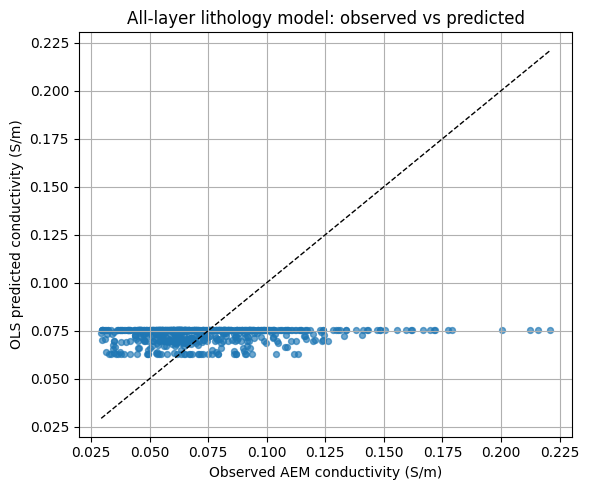

In [49]:
plt.figure(figsize=(6, 5))
plt.scatter(b_all, predicted_conductivity, s=18, alpha=0.65)
limits = [min(b_all.min(), predicted_conductivity.min()), max(b_all.max(), predicted_conductivity.max())]
plt.plot(limits, limits, "k--", linewidth=1)
plt.xlabel("Observed AEM conductivity (S/m)")
plt.ylabel("OLS predicted conductivity (S/m)")
plt.title("All-layer lithology model: observed vs predicted")
plt.grid()
plt.tight_layout()
plt.show()

In [50]:
# Non-negative least squares.
from scipy.optimize import nnls

def run_bootstrap_inversion_by_equation(A_equations, b_equations, iterations=1000, rng=None):
    """Bootstrap equations and return nonnegative conductivity estimates."""
    A = np.asarray(A_equations, dtype=float)
    b = np.asarray(b_equations, dtype=float).reshape(-1)
    if A.ndim != 2 or A.shape[0] != b.size:
        raise ValueError("A_equations and b_equations must contain the same number of equations.")
    if A.shape[0] == 0:
        raise ValueError("At least one equation is required.")
    if iterations <= 0:
        raise ValueError("iterations must be a positive integer.")

    n_equations, n_lithologies = A.shape
    rng = np.random.default_rng() if rng is None else rng
    bootstrap_conductivities = np.full((iterations, n_lithologies), np.nan)

    for iteration in range(iterations):
        sampled_equations = rng.integers(0, n_equations, size=n_equations)
        A_resampled = A[sampled_equations]
        b_resampled = b[sampled_equations]

        if np.linalg.matrix_rank(A_resampled) < n_lithologies:
            continue

        conductivity, _ = nnls(A_resampled, b_resampled)
        bootstrap_conductivities[iteration] = conductivity

    return bootstrap_conductivities

In [51]:
rng = np.random.default_rng(42)
bootstrap_conductivity_all = run_bootstrap_inversion_by_equation(
    A_all,
    b_all,
    iterations=1000,
    rng=rng,
)

valid_bootstrap = bootstrap_conductivity_all[
    np.isfinite(bootstrap_conductivity_all).all(axis=1)
]
print(
    f"All-depth equation bootstrap: {len(valid_bootstrap)}/"
    f"{len(bootstrap_conductivity_all)} valid fits; "
    f"{A_all.shape[0]} equations sampled per iteration."
)
if len(valid_bootstrap) == 0:
    raise ValueError("No full-rank bootstrap fits were available for the all-depth model.")

bootstrap_conductivity_above = run_bootstrap_inversion_by_equation(
    A_above_grid, b_above_grid, iterations=1000, rng=rng
)
bootstrap_conductivity_below = run_bootstrap_inversion_by_equation(
    A_below_grid, b_below_grid, iterations=1000, rng=rng
)
valid_bootstrap_above = bootstrap_conductivity_above[
    np.isfinite(bootstrap_conductivity_above).all(axis=1)
]
valid_bootstrap_below = bootstrap_conductivity_below[
    np.isfinite(bootstrap_conductivity_below).all(axis=1)
]
print(f"Above-grid-DTW bootstrap: {len(valid_bootstrap_above)}/1000 valid fits")
print(f"Below-grid-DTW bootstrap: {len(valid_bootstrap_below)}/1000 valid fits")
if len(valid_bootstrap_above) == 0 or len(valid_bootstrap_below) == 0:
    raise ValueError("No full-rank bootstrap fits were available for one DTW group.")

All-depth equation bootstrap: 1000/1000 valid fits; 694 equations sampled per iteration.

Above-grid-DTW bootstrap: 1000/1000 valid fits

Below-grid-DTW bootstrap: 1000/1000 valid fits

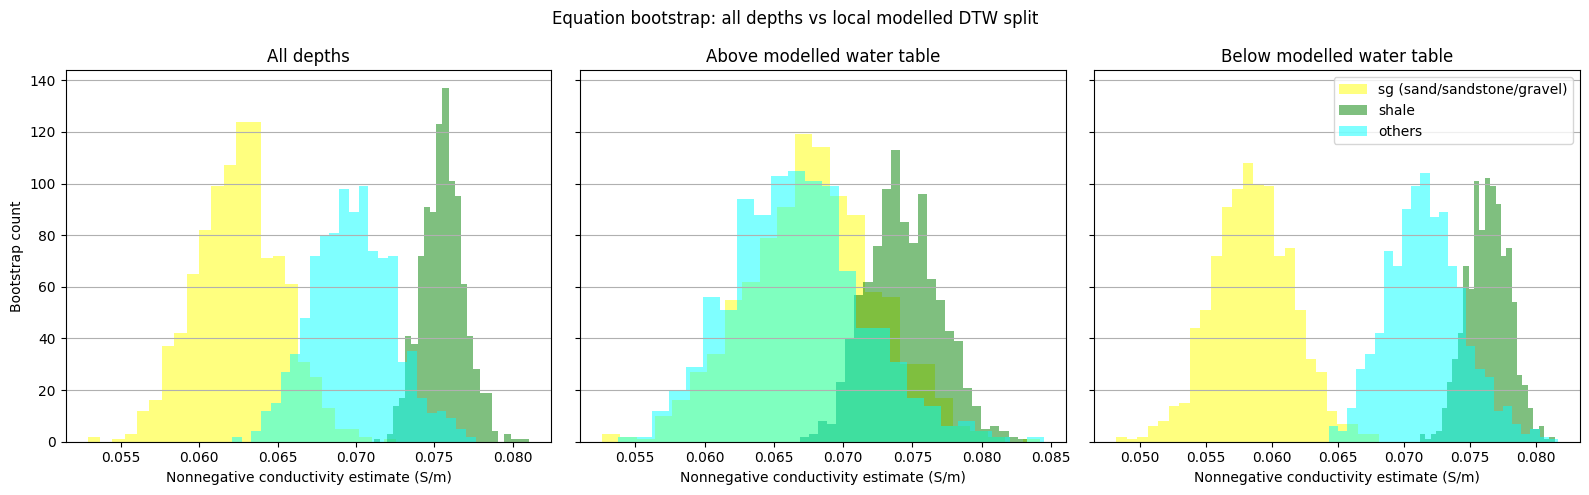

In [52]:
bootstrap_groups = {
    "All depths": valid_bootstrap,
    "Above modelled water table": valid_bootstrap_above,
    "Below modelled water table": valid_bootstrap_below,
}
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for axis, (group_name, values) in zip(axes, bootstrap_groups.items()):
    for class_idx, label in enumerate(lithology_labels):
        axis.hist(
            values[:, class_idx],
            bins=25,
            alpha=0.5,
            label=label,
            color=allocate_color(("sg", "shale", "others")[class_idx]),
        )
    axis.set_xlabel("Nonnegative conductivity estimate (S/m)")
    axis.set_title(group_name)
    axis.grid(axis="y")
axes[0].set_ylabel("Bootstrap count")
axes[-1].legend()
fig.suptitle("Equation bootstrap: all depths vs local modelled DTW split")
fig.tight_layout()

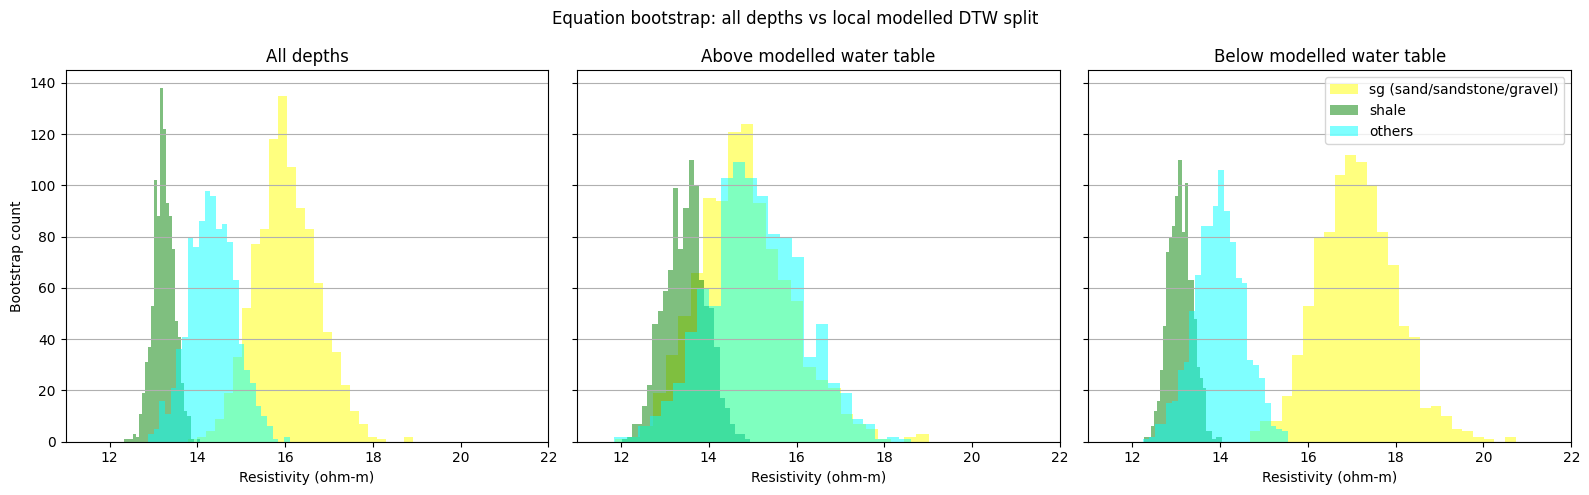

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for axis, (group_name, values) in zip(axes, bootstrap_groups.items()):
    for class_idx, label in enumerate(lithology_labels):
        axis.hist(
            1/values[:, class_idx],
            bins=25,
            alpha=0.5,
            label=label,
            color=allocate_color(("sg", "shale", "others")[class_idx]),
        )
    axis.set_xlabel("Resistivity (ohm-m)")
    axis.set_title(group_name)
    axis.grid(axis="y")
    axis.set_xlim(11, 22)
axes[0].set_ylabel("Bootstrap count")
axes[-1].legend()
fig.suptitle("Equation bootstrap: all depths vs local modelled DTW split")
fig.tight_layout()

In [54]:
for group_name, values in bootstrap_groups.items():
    print(f"{group_name}:")
    for class_idx, label in enumerate(lithology_labels):
        samples = values[:, class_idx]
        lower, median, upper = np.quantile(samples, [0.025, 0.5, 0.975])
        zero_fraction = np.mean(samples <= np.finfo(float).eps)
        print(
            "================================================================\n"
            f"- {label}: median={1/median:.5g} ohm-m,\n"
            f"- 95% bootstrap interval=[{1/lower:.5g}, {1/upper:.5g}] ohm-m,\n"
            f"- zero-boundary fits={zero_fraction:.1%}"
            "\n================================================================\n"
        )

All depths:

================================================================
- sg (sand/sandstone/gravel): median=15.979 ohm-m,
- 95% bootstrap interval=[17.449, 14.709] ohm-m,
- zero-boundary fits=0.0%
================================================================

================================================================
- shale: median=13.234 ohm-m,
- 95% bootstrap interval=[13.693, 12.761] ohm-m,
- zero-boundary fits=0.0%
================================================================

================================================================
- others: median=14.338 ohm-m,
- 95% bootstrap interval=[15.384, 13.293] ohm-m,
- zero-boundary fits=0.0%
================================================================

Above modelled water table:

...

================================================================
- others: median=15.017 ohm-m,
- 95% bootstrap interval=[17.168, 13.075] ohm-m,
- zero-boundary fits=0.0%
================================================================

Below modelled water table:

================================================================
- sg (sand/sandstone/gravel): median=17.087 ohm-m,
- 95% bootstrap interval=[18.977, 15.482] ohm-m,
- zero-boundary fits=0.0%
================================================================

================================================================
- shale: median=13.089 ohm-m,
- 95% bootstrap interval=[13.639, 12.582] ohm-m,
- zero-boundary fits=0.0%
================================================================

================================================================
- others: median=13.984 ohm-m,
- 95% bootstrap interval=[15.04, 12.842] ohm-m,
- zero-boundary fits=0.0%
================================================================